<a href="https://colab.research.google.com/github/Koroush-Mashayekh/diabetes-risk-prediction/blob/main/notebooks/03_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Risk Prediction: Final Evaluation

The model selected in [`02_modeling.ipynb`](02_modeling.ipynb), **Logistic Regression (balanced)**,
is trained on the full training set and evaluated **once** on the held-out test set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

URL = "https://raw.githubusercontent.com/Koroush-Mashayekh/diabetes-risk-prediction/main/data/diabetes.csv"
df = pd.read_csv(URL)

X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

cols_with_hidden_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
X_train = X_train.copy()
X_test = X_test.copy()
X_train[cols_with_hidden_missing] = X_train[cols_with_hidden_missing].replace(0, np.nan)
X_test[cols_with_hidden_missing] = X_test[cols_with_hidden_missing].replace(0, np.nan)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (614, 8)  Test: (154, 8)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

final_model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

## 1. Test set performance

In [3]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score

y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

print("ROC-AUC:  ", round(roc_auc_score(y_test, y_proba), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Accuracy: ", round(accuracy_score(y_test, y_pred), 3))

ROC-AUC:   0.813
Recall:    0.704
Precision: 0.603
Accuracy:  0.734


**Result (test set, n = 154):**

| Metric    | CV (train)    | Test  |
|-----------|---------------|-------|
| ROC-AUC   | 0.844 ± 0.016 | 0.813 |
| Recall    | 0.701         | 0.704 |
| Precision | –             | 0.603 |
| Accuracy  | 0.762         | 0.734 |

- The model detects **38 of 54** diabetic patients (recall 0.70) and misses **16**.
- **25 of 100** non-diabetic patients receive a false alarm (precision 0.60).
- Test performance is consistent with cross-validation. The slightly lower ROC-AUC is expected
  given the small test set, where a few samples can shift the score noticeably.
- In a screening context, false alarms (leading to a follow-up test) are generally less costly
  than missed patients, which motivated the use of `class_weight="balanced"`.

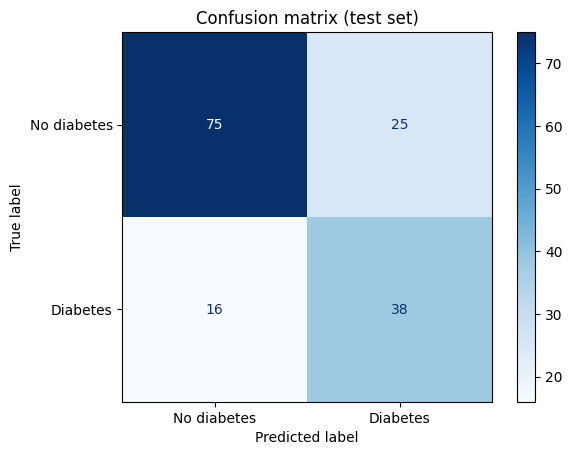

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No diabetes", "Diabetes"],
    cmap="Blues"
)
plt.title("Confusion matrix (test set)")
plt.show()